# 🧹 ITC Hotels — Data Cleaning & Exploratory Data Analysis (EDA)

**Project:** ITC Hotels Revenue & Business Performance Analysis  
**Dataset:** Kaggle Hotel Booking Demand (119,390 raw records)  
**Tools:** Python, Pandas, Matplotlib, SQLite  
**Author:** Jatin Sagar | Invertis University, Bareilly

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import sqlite3
import warnings
warnings.filterwarnings('ignore')

# matplotlib settings - professional look
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.style.use('seaborn-v0_8-darkgrid')

print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")

Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2


## 1. Loading Raw Dataset
Loading the original Kaggle "Hotel Booking Demand" dataset to inspect its raw state before any cleaning.

In [2]:
# Load raw Kaggle dataset
raw_df = pd.read_csv('../archive/hotel_bookings.csv')
print(f"Dataset Shape: {raw_df.shape[0]} rows × {raw_df.shape[1]} columns")
print(f"\nMemory Usage: {raw_df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
raw_df.head()

Dataset Shape: 119390 rows × 32 columns

Memory Usage: 98.47 MB


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Data Inspection
Checking data types, null values, and basic statistics.

In [3]:
# Data types and non-null counts
print("=" * 60)
print("DATA TYPES & NULL ANALYSIS")
print("=" * 60)
raw_df.info()

DATA TYPES & NULL ANALYSIS
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  

In [4]:
# Null value analysis
null_analysis = pd.DataFrame({
    'Column': raw_df.columns,
    'Null_Count': raw_df.isnull().sum().values,
    'Null_Pct': (raw_df.isnull().sum().values / len(raw_df) * 100).round(2),
    'Dtype': raw_df.dtypes.values
})
null_analysis = null_analysis[null_analysis['Null_Count'] > 0].sort_values('Null_Count', ascending=False)
print("\nColumns with Missing Values:")
print(null_analysis.to_string(index=False))


Columns with Missing Values:
  Column  Null_Count  Null_Pct   Dtype
 company      112593     94.31 float64
   agent       16340     13.69 float64
 country         488      0.41     str
children           4      0.00 float64


In [5]:
# Statistical summary - numerical columns
raw_df.describe().round(2)

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119386.0,119390.00,119390.00,119390.00,119390.00,119390.00,103050.00,6797.00,119390.00,119390.00,119390.00,119390.00
mean,0.37,104.01,2016.16,27.17,15.80,0.93,2.50,1.86,0.1,0.01,0.03,0.09,0.14,0.22,86.69,189.27,2.32,101.83,0.06,0.57
std,0.48,106.86,0.71,13.61,8.78,1.00,1.91,0.58,0.4,0.10,0.18,0.84,1.50,0.65,110.77,131.66,17.59,50.54,0.25,0.79
min,0.00,0.00,2015.00,1.00,1.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00,6.00,0.00,-6.38,0.00,0.00
25%,0.00,18.00,2016.00,16.00,8.00,0.00,1.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,9.00,62.00,0.00,69.29,0.00,0.00
50%,0.00,69.00,2016.00,28.00,16.00,1.00,2.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,14.00,179.00,0.00,94.58,0.00,0.00
75%,1.00,160.00,2017.00,38.00,23.00,2.00,3.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,229.00,270.00,0.00,126.00,0.00,1.00
max,1.00,737.00,2017.00,53.00,31.00,19.00,50.00,55.00,10.0,10.00,1.00,26.00,72.00,21.00,535.00,543.00,391.00,5400.00,8.00,5.00


## 3. Data Cleaning Pipeline

### Step 3.1: Handle Missing Values

In [6]:
# Step 3.1: Fix missing values
print("BEFORE CLEANING:")
print(f"  Total rows: {len(raw_df)}")
print(f"  'children' nulls: {raw_df['children'].isnull().sum()}")
print(f"  'country' nulls: {raw_df['country'].isnull().sum()}")
print(f"  'agent' = NULL (string): {(raw_df['agent'] == 'NULL').sum()}")
print(f"  'company' = NULL (string): {(raw_df['company'] == 'NULL').sum()}")

# Fix children - fill with 0
raw_df['children'] = raw_df['children'].fillna(0).astype(int)

# Fix country - fill with 'Unknown'
raw_df['country'] = raw_df['country'].fillna('Unknown')

# Agent and Company have 'NULL' as string, not actual NaN
raw_df['agent'] = raw_df['agent'].replace('NULL', np.nan)
raw_df['company'] = raw_df['company'].replace('NULL', np.nan)

print("\nAFTER CLEANING:")
print(f"  'children' nulls: {raw_df['children'].isnull().sum()}")
print(f"  'country' nulls: {raw_df['country'].isnull().sum()}")

BEFORE CLEANING:
  Total rows: 119390
  'children' nulls: 4
  'country' nulls: 488
  'agent' = NULL (string): 0
  'company' = NULL (string): 0

AFTER CLEANING:
  'children' nulls: 0
  'country' nulls: 0


### Step 3.2: Remove Duplicates

In [7]:
# Step 3.2: Duplicate detection and removal
dupes = raw_df.duplicated().sum()
print(f"Duplicate rows found: {dupes} ({dupes/len(raw_df)*100:.1f}%)")

raw_df = raw_df.drop_duplicates().reset_index(drop=True)
print(f"After removing duplicates: {len(raw_df)} rows remaining")

Duplicate rows found: 31994 (26.8%)


After removing duplicates: 87396 rows remaining


### Step 3.3: Fix Outliers & Anomalies

In [8]:
# Step 3.3a: Check for negative ADR values
neg_adr = raw_df[raw_df['adr'] < 0]
print(f"Negative ADR values: {len(neg_adr)}")
if len(neg_adr) > 0:
    print(neg_adr[['hotel', 'adr', 'arrival_date_month']].head())

# Fix: replace negative ADR with column median
median_adr = raw_df.loc[raw_df['adr'] >= 0, 'adr'].median()
raw_df.loc[raw_df['adr'] < 0, 'adr'] = median_adr
print(f"Replaced with median ADR: €{median_adr:.2f}")

Negative ADR values: 1
              hotel   adr arrival_date_month
11591  Resort Hotel -6.38              March
Replaced with median ADR: €98.10


Extreme ADR outliers (>€5000): 1


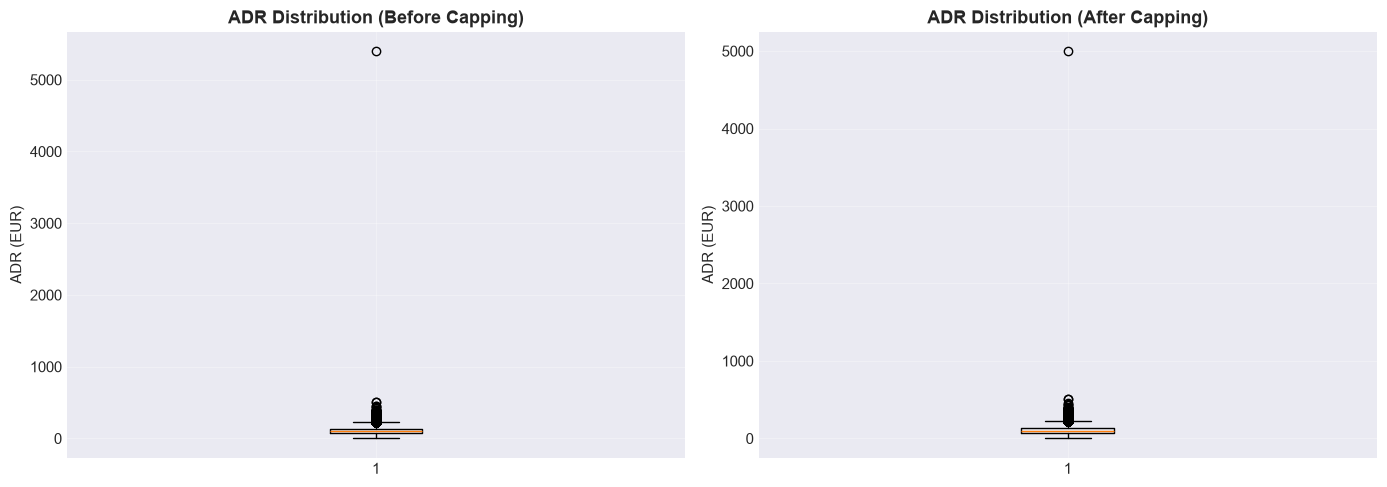

✓ Outlier chart saved


In [9]:
# Step 3.3b: Check for extreme outliers in ADR
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before capping
axes[0].boxplot(raw_df['adr'], vert=True)
axes[0].set_title('ADR Distribution (Before Capping)', fontweight='bold')
axes[0].set_ylabel('ADR (EUR)')

# Cap extreme outliers at 5000 EUR
outliers = (raw_df['adr'] > 5000).sum()
print(f"Extreme ADR outliers (>€5000): {outliers}")
raw_df.loc[raw_df['adr'] > 5000, 'adr'] = 5000

# After capping
axes[1].boxplot(raw_df['adr'], vert=True)
axes[1].set_title('ADR Distribution (After Capping)', fontweight='bold')
axes[1].set_ylabel('ADR (EUR)')

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_adr_outliers.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Outlier chart saved")

### Step 3.4: Create Derived Columns

In [10]:
# Step 3.4: Feature engineering
raw_df['arrival_date'] = pd.to_datetime(
    raw_df['arrival_date_year'].astype(str) + '-' +
    raw_df['arrival_date_month'] + '-' +
    raw_df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)

raw_df['total_nights'] = raw_df['stays_in_weekend_nights'] + raw_df['stays_in_week_nights']
raw_df['total_guests'] = raw_df['adults'] + raw_df['children'] + raw_df['babies']

# Convert ADR to INR (EUR × 85)
raw_df['adr_inr'] = round(raw_df['adr'] * 85, 2)
raw_df['room_revenue_inr'] = round(raw_df['adr_inr'] * raw_df['total_nights'], 2)

print(f"New columns created: arrival_date, total_nights, total_guests, adr_inr, room_revenue_inr")
print(f"\nDate range: {raw_df['arrival_date'].min()} to {raw_df['arrival_date'].max()}")
print(f"Dataset now has {len(raw_df.columns)} columns")

New columns created: arrival_date, total_nights, total_guests, adr_inr, room_revenue_inr

Date range: 2015-07-01 00:00:00 to 2017-08-31 00:00:00
Dataset now has 37 columns


---
## 4. Exploratory Data Analysis (EDA) — Matplotlib Visualizations

### 4.1: Hotel Type Distribution

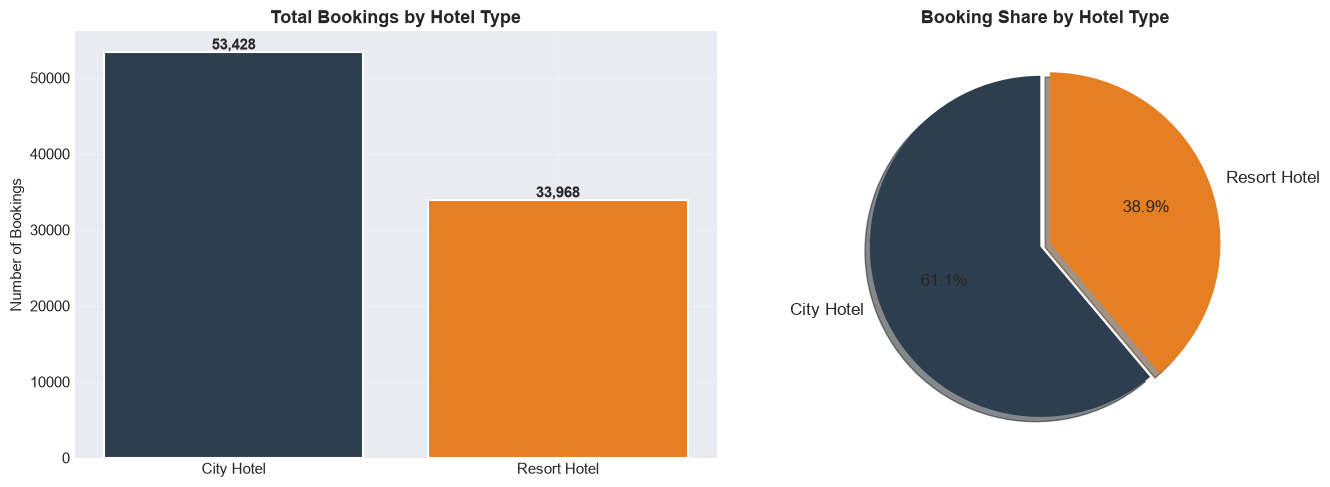

In [11]:
# 4.1: Hotel type comparison
hotel_counts = raw_df['hotel'].value_counts()
colors = ['#2C3E50', '#E67E22']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].bar(hotel_counts.index, hotel_counts.values, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Total Bookings by Hotel Type', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Number of Bookings')
for bar, val in zip(bars, hotel_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                f'{val:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(hotel_counts.values, labels=hotel_counts.index, colors=colors,
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12},
            explode=(0.03, 0.03), shadow=True)
axes[1].set_title('Booking Share by Hotel Type', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_hotel_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2: Monthly Booking Trends & Seasonality

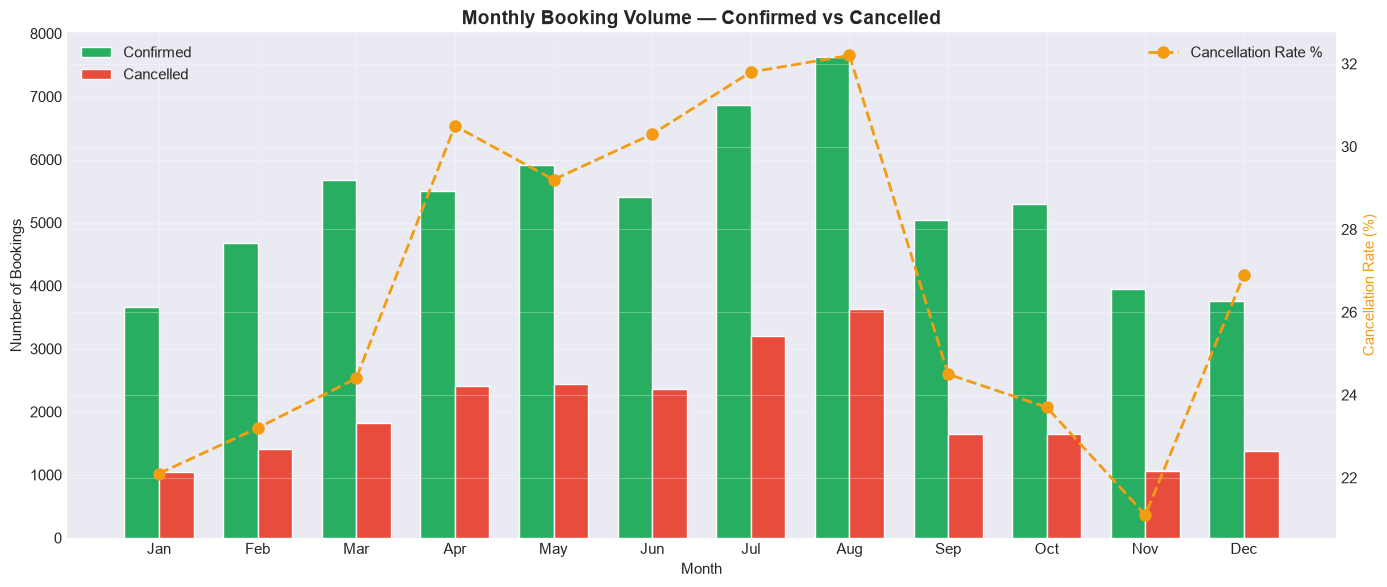

In [12]:
# 4.2: Monthly booking trend
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

monthly = raw_df.groupby('arrival_date_month').agg(
    total_bookings=('hotel', 'count'),
    cancellations=('is_canceled', 'sum'),
    avg_adr=('adr', 'mean')
).reindex(month_order)

monthly['confirmed'] = monthly['total_bookings'] - monthly['cancellations']
monthly['cancel_rate'] = (monthly['cancellations'] / monthly['total_bookings'] * 100).round(1)

fig, ax1 = plt.subplots(figsize=(14, 6))

x = range(len(month_order))
width = 0.35

bars1 = ax1.bar([i - width/2 for i in x], monthly['confirmed'], width,
                label='Confirmed', color='#27AE60', edgecolor='white')
bars2 = ax1.bar([i + width/2 for i in x], monthly['cancellations'], width,
                label='Cancelled', color='#E74C3C', edgecolor='white')

ax1.set_xlabel('Month')
ax1.set_ylabel('Number of Bookings')
ax1.set_title('Monthly Booking Volume — Confirmed vs Cancelled', fontweight='bold', fontsize=14)
ax1.set_xticks(x)
ax1.set_xticklabels([m[:3] for m in month_order], rotation=0)
ax1.legend(loc='upper left')

# Cancellation rate line on secondary axis
ax2 = ax1.twinx()
ax2.plot(x, monthly['cancel_rate'], 'o--', color='#F39C12', linewidth=2,
         markersize=8, label='Cancellation Rate %')
ax2.set_ylabel('Cancellation Rate (%)', color='#F39C12')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_monthly_trends.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3: ADR Distribution by Room Type

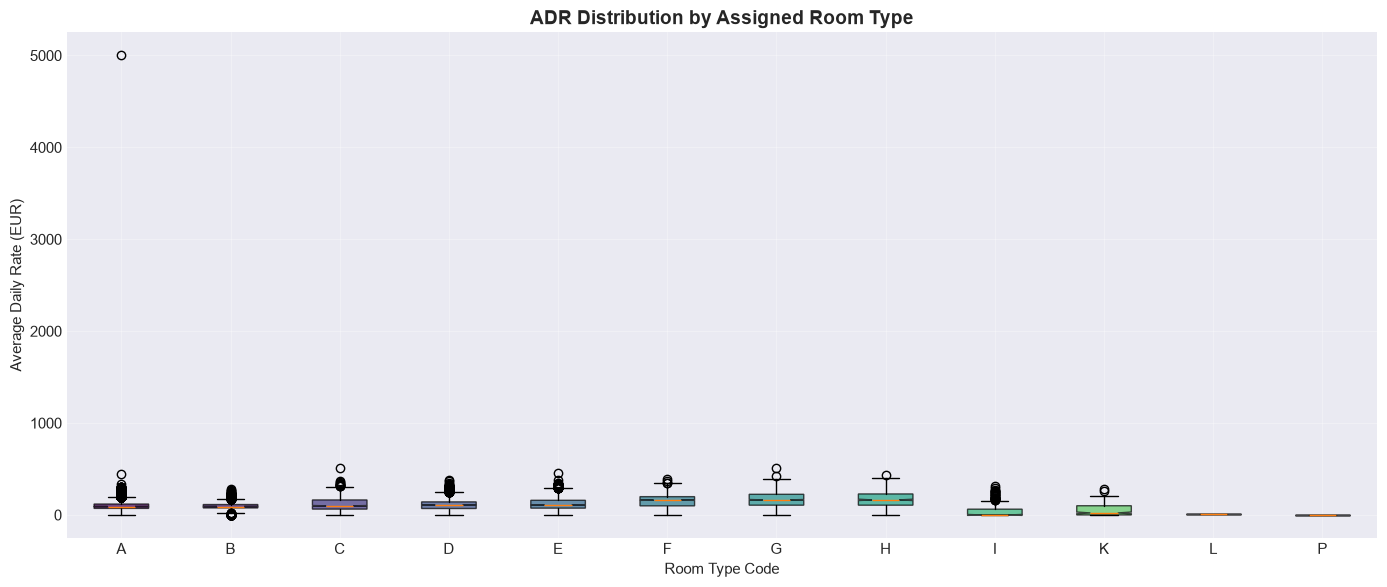

In [13]:
# 4.3: ADR by room type (boxplot)
fig, ax = plt.subplots(figsize=(14, 6))

room_types = sorted(raw_df['assigned_room_type'].unique())
data_by_room = [raw_df[raw_df['assigned_room_type'] == rt]['adr'].values for rt in room_types]

bp = ax.boxplot(data_by_room, tick_labels=room_types, patch_artist=True, notch=True)

cmap = plt.cm.viridis
colors_box = [cmap(i / len(room_types)) for i in range(len(room_types))]
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title('ADR Distribution by Assigned Room Type', fontweight='bold', fontsize=14)
ax.set_xlabel('Room Type Code')
ax.set_ylabel('Average Daily Rate (EUR)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_adr_by_room.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.4: Country-wise Guest Distribution (Top 15)

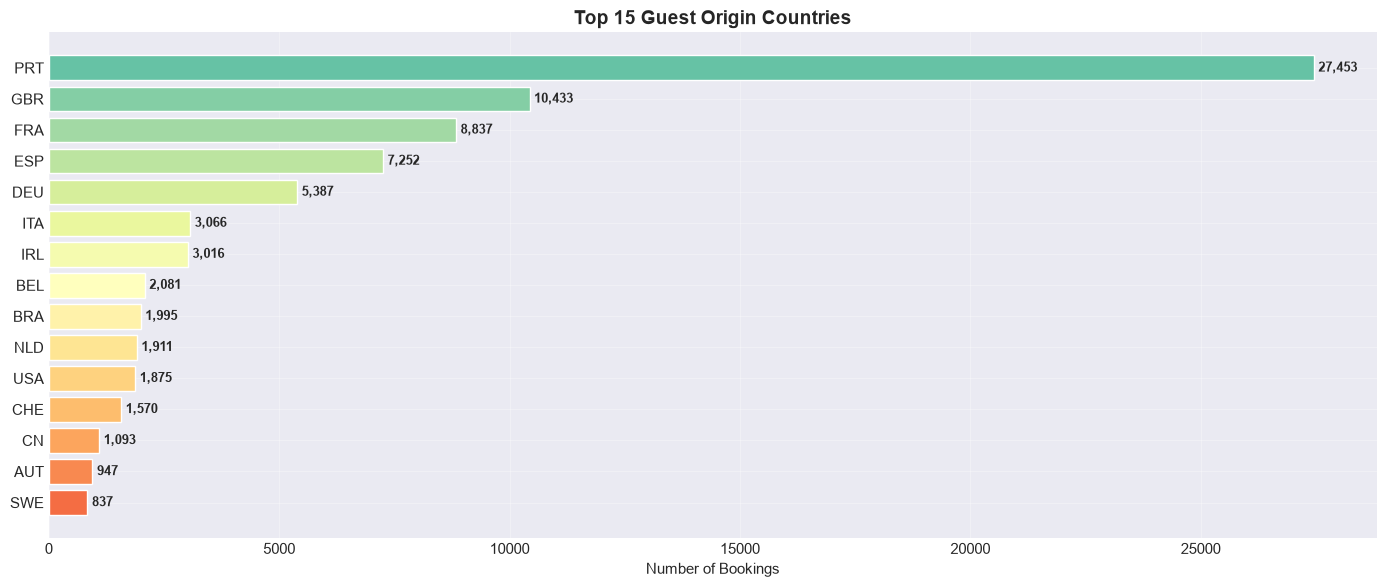

In [14]:
# 4.4: Top 15 countries
top_countries = raw_df['country'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.barh(top_countries.index[::-1], top_countries.values[::-1],
               color=plt.cm.Spectral(np.linspace(0.2, 0.8, 15)), edgecolor='white')

ax.set_title('Top 15 Guest Origin Countries', fontweight='bold', fontsize=14)
ax.set_xlabel('Number of Bookings')

for bar, val in zip(bars, top_countries.values[::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_country_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.5: Cancellation Analysis

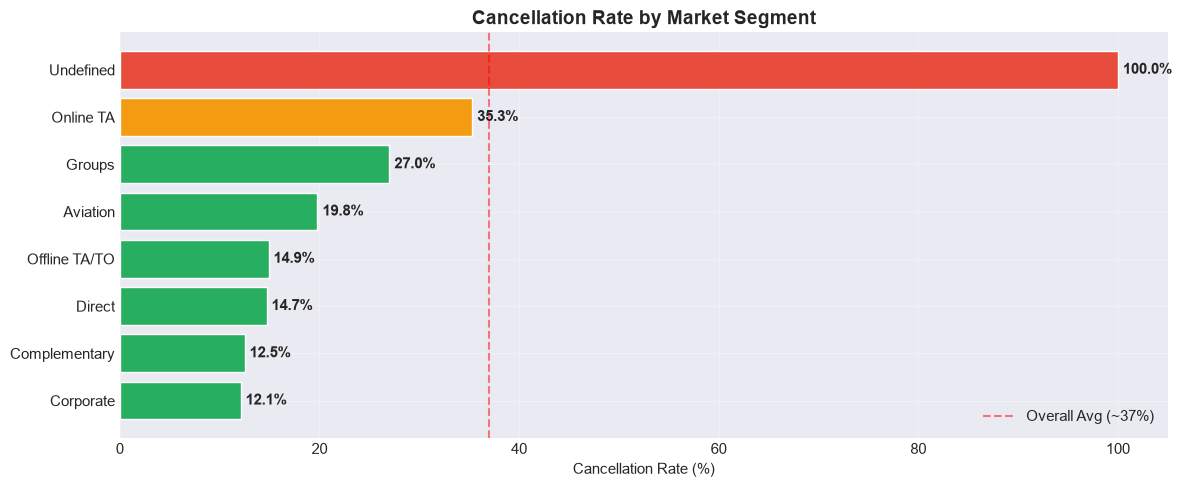

In [15]:
# 4.5: Cancellation by market segment
cancel_by_segment = raw_df.groupby('market_segment').agg(
    total=('is_canceled', 'count'),
    cancelled=('is_canceled', 'sum')
)
cancel_by_segment['cancel_rate'] = (cancel_by_segment['cancelled'] / cancel_by_segment['total'] * 100).round(1)
cancel_by_segment = cancel_by_segment.sort_values('cancel_rate', ascending=True)

fig, ax = plt.subplots(figsize=(12, 5))

colors_cancel = ['#27AE60' if r < 30 else '#F39C12' if r < 45 else '#E74C3C' 
                  for r in cancel_by_segment['cancel_rate']]

bars = ax.barh(cancel_by_segment.index, cancel_by_segment['cancel_rate'],
               color=colors_cancel, edgecolor='white', linewidth=1)

ax.set_title('Cancellation Rate by Market Segment', fontweight='bold', fontsize=14)
ax.set_xlabel('Cancellation Rate (%)')
ax.axvline(x=37, color='red', linestyle='--', alpha=0.5, label='Overall Avg (~37%)')
ax.legend()

for bar, val in zip(bars, cancel_by_segment['cancel_rate']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_cancellation_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.6: Lead Time Distribution

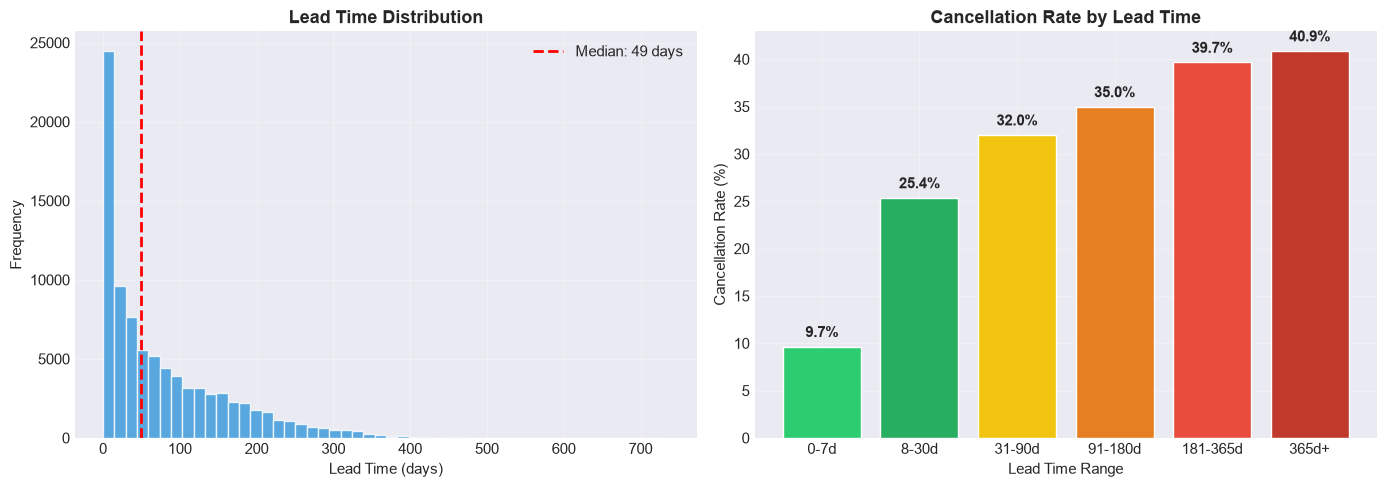

In [16]:
# 4.6: Lead time distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(raw_df['lead_time'], bins=50, color='#3498DB', edgecolor='white', alpha=0.8)
axes[0].axvline(raw_df['lead_time'].median(), color='red', linestyle='--', linewidth=2,
                label=f'Median: {raw_df["lead_time"].median():.0f} days')
axes[0].set_title('Lead Time Distribution', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Lead Time (days)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Lead time vs Cancellation
lead_bins = pd.cut(raw_df['lead_time'], bins=[0, 7, 30, 90, 180, 365, 800],
                   labels=['0-7d', '8-30d', '31-90d', '91-180d', '181-365d', '365d+'])
cancel_by_lead = raw_df.groupby(lead_bins, observed=False)['is_canceled'].mean() * 100

axes[1].bar(range(len(cancel_by_lead)), cancel_by_lead.values,
            color=['#2ECC71', '#27AE60', '#F1C40F', '#E67E22', '#E74C3C', '#C0392B'],
            edgecolor='white')
axes[1].set_title('Cancellation Rate by Lead Time', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Lead Time Range')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].set_xticks(range(len(cancel_by_lead)))
axes[1].set_xticklabels(cancel_by_lead.index, rotation=0)

for i, val in enumerate(cancel_by_lead.values):
    axes[1].text(i, val + 1, f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_lead_time.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.7: Revenue Heatmap — Year × Month

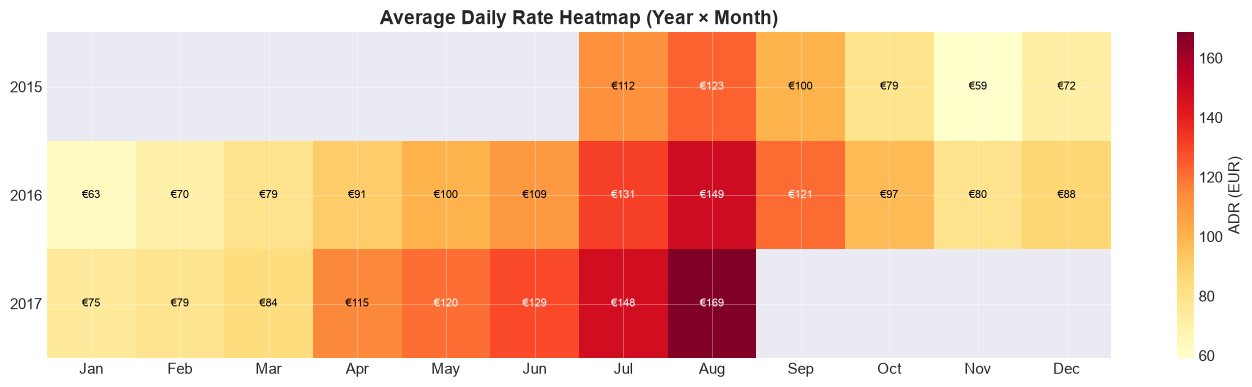

In [17]:
# 4.7: Revenue heatmap
rev_pivot = raw_df.pivot_table(values='adr', index='arrival_date_year',
                                columns='arrival_date_month', aggfunc='mean')
rev_pivot = rev_pivot[month_order]

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(rev_pivot.values, cmap='YlOrRd', aspect='auto')

ax.set_xticks(range(12))
ax.set_xticklabels([m[:3] for m in month_order])
ax.set_yticks(range(len(rev_pivot.index)))
ax.set_yticklabels(rev_pivot.index)
ax.set_title('Average Daily Rate Heatmap (Year × Month)', fontweight='bold', fontsize=14)

# Add text annotations
for i in range(len(rev_pivot.index)):
    for j in range(12):
        val = rev_pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'€{val:.0f}', ha='center', va='center',
                    fontsize=8, color='black' if val < 120 else 'white')

plt.colorbar(im, ax=ax, label='ADR (EUR)')
plt.tight_layout()
plt.savefig('../ITC-Final-Dashboards/eda_revenue_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. SQL Database Queries

Now connecting to the SQLite database to demonstrate SQL-based analytics.

In [18]:
# Connect to SQLite database
conn = sqlite3.connect('../ITC-Final-Dashboards/itc_hotel_analytics.db')
cursor = conn.cursor()

# Check all tables
tables = cursor.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name").fetchall()
print("Database Tables:")
print("-" * 40)
for t in tables:
    count = cursor.execute(f"SELECT COUNT(*) FROM {t[0]}").fetchone()[0]
    print(f"  {t[0]:<25} {count:>8,} rows")

Database Tables:
----------------------------------------
  banquet_events              69,679 rows
  fnb_orders                  87,396 rows
  guests                      87,396 rows
  hotels                           2 rows
  invoices                    87,396 rows
  kpi_monthly                     26 rows
  operating_costs             87,396 rows
  payments                    63,371 rows
  reservations                87,396 rows
  room_types                      11 rows
  sqlite_sequence                 12 rows
  staff                           10 rows
  users                            5 rows


In [19]:
# SQL Query 1: Monthly Revenue Summary
query_revenue = """
SELECT r.arrival_year AS Year,
       r.arrival_month AS Month,
       COUNT(*) AS Total_Bookings,
       SUM(CASE WHEN r.is_canceled = 0 THEN 1 ELSE 0 END) AS Confirmed,
       ROUND(AVG(i.adr_inr), 2) AS Avg_ADR_INR,
       ROUND(SUM(i.room_revenue_inr) / 10000000, 2) AS Room_Revenue_Cr,
       ROUND(SUM(i.gross_total_revenue_inr) / 10000000, 2) AS Gross_Revenue_Cr
FROM reservations r
JOIN invoices i ON r.booking_id = i.booking_id
WHERE r.is_canceled = 0
GROUP BY r.arrival_year, r.arrival_month
ORDER BY r.arrival_year, 
    CASE r.arrival_month
        WHEN 'January' THEN 1 WHEN 'February' THEN 2 WHEN 'March' THEN 3
        WHEN 'April' THEN 4 WHEN 'May' THEN 5 WHEN 'June' THEN 6
        WHEN 'July' THEN 7 WHEN 'August' THEN 8 WHEN 'September' THEN 9
        WHEN 'October' THEN 10 WHEN 'November' THEN 11 WHEN 'December' THEN 12
    END
"""

revenue_df = pd.read_sql_query(query_revenue, conn)
print("Monthly Revenue Summary (SQL Query):")
revenue_df.head(12)

Monthly Revenue Summary (SQL Query):


,Year,Month,Total_Bookings,Confirmed,Avg_ADR_INR,Room_Revenue_Cr,Gross_Revenue_Cr
0,2015,July,1162,1162,9893.40,5.72,30.88
1,2015,August,1882,1882,10317.14,8.85,50.72
2,2015,September,2273,2273,8524.67,7.35,56.84
3,2015,October,2260,2260,6678.53,4.90,54.48
4,2015,November,1422,1422,4946.51,2.27,33.89
5,2015,December,1610,1610,5912.48,2.90,36.92
6,2016,January,1548,1548,5192.71,2.05,33.65
7,2016,February,2278,2278,5858.59,3.75,51.94
8,2016,March,2945,2945,6348.11,5.79,68.29
9,2016,April,2756,2756,7434.97,6.53,66.10


In [20]:
# SQL Query 2: Top 10 countries by guest count
query_countries = """
SELECT g.country_code AS Country,
       g.geographic_region AS Region,
       COUNT(*) AS Total_Guests,
       SUM(g.is_repeated_guest) AS Repeat_Guests,
       ROUND(AVG(g.total_guests), 1) AS Avg_Party_Size
FROM guests g
JOIN reservations r ON g.booking_id = r.booking_id
WHERE r.is_canceled = 0
GROUP BY g.country_code
ORDER BY Total_Guests DESC
LIMIT 10
"""

countries_df = pd.read_sql_query(query_countries, conn)
print("Top 10 Countries by Guest Volume (SQL):")
countries_df

Top 10 Countries by Guest Volume (SQL):


,Country,Region,Total_Guests,Repeat_Guests,Avg_Party_Size
0,PRT,Europe,17662,2637,1.8
1,GBR,Europe,8448,106,2.0
2,FRA,Europe,7104,70,2.1
3,ESP,Europe,5390,83,2.1
4,DEU,Europe,4334,21,2.0
5,IRL,Europe,2348,29,2.0
6,ITA,Europe,1991,35,2.0
7,BEL,Europe,1670,16,2.1
8,NLD,Europe,1561,20,2.0
9,USA,North America,1416,18,2.0


In [21]:
# SQL Query 3: KPI Dashboard from kpi_monthly table
query_kpi = """
SELECT year, month, month_num,
       total_bookings, total_cancellations,
       ROUND(occupancy_rate_pct, 1) AS Occupancy_Pct,
       ROUND(avg_daily_rate_inr, 0) AS ADR_INR,
       ROUND(revpar_inr, 0) AS RevPAR_INR,
       ROUND(gross_revenue / 10000000, 2) AS Gross_Rev_Cr,
       ROUND(gross_operating_profit / 10000000, 2) AS GOP_Cr,
       ROUND(gop_margin_pct, 1) AS GOP_Margin
FROM kpi_monthly
ORDER BY year, month_num
"""

kpi_df = pd.read_sql_query(query_kpi, conn)
print("KPI Monthly Dashboard (from SQL):")
kpi_df

KPI Monthly Dashboard (from SQL):


,year,month,month_num,total_bookings,total_cancellations,Occupancy_Pct,ADR_INR,RevPAR_INR,Gross_Rev_Cr,GOP_Cr,GOP_Margin
0,2015,July,7,1674,512,69.4,9893.0,3521.0,30.88,28.33,91.7
1,2015,August,8,2453,571,76.7,10317.0,5445.0,50.72,46.91,92.5
2,2015,September,9,2839,566,80.1,8525.0,4521.0,56.84,53.02,93.3
3,2015,October,10,2700,440,83.7,6679.0,3011.0,54.48,51.53,94.6
4,2015,November,11,1665,243,85.4,4947.0,1396.0,33.89,32.23,95.1
5,2015,December,12,1982,372,81.2,5912.0,1784.0,36.92,35.09,95.0
6,2016,January,1,1849,301,83.7,5193.0,1263.0,33.65,32.19,95.6
7,2016,February,2,2806,528,81.2,5859.0,2306.0,51.94,49.46,95.2
8,2016,March,3,3831,886,76.9,6348.0,3559.0,68.29,64.72,94.8
9,2016,April,4,3770,1014,73.1,7435.0,4014.0,66.10,62.43,94.4


In [22]:
# SQL Query 4: F&B Performance by Restaurant
query_fnb = """
SELECT f.restaurant_outlet AS Restaurant,
       COUNT(*) AS Total_Orders,
       ROUND(SUM(f.food_revenue_inr) / 100000, 2) AS Food_Rev_Lakhs,
       ROUND(SUM(f.beverage_revenue_inr) / 100000, 2) AS Bev_Rev_Lakhs,
       ROUND(SUM(f.total_fnb_revenue_inr) / 100000, 2) AS Total_FnB_Lakhs,
       ROUND(AVG(f.dining_covers), 1) AS Avg_Covers
FROM fnb_orders f
JOIN reservations r ON f.booking_id = r.booking_id
WHERE r.is_canceled = 0 AND f.dining_covers > 0
GROUP BY f.restaurant_outlet
ORDER BY Total_FnB_Lakhs DESC
"""

fnb_df = pd.read_sql_query(query_fnb, conn)
print("F&B Performance by Restaurant (SQL):")
fnb_df

F&B Performance by Restaurant (SQL):


,Restaurant,Total_Orders,Food_Rev_Lakhs,Bev_Rev_Lakhs,Total_FnB_Lakhs,Avg_Covers
0,West View,10605,322.50,80.74,403.25,2.0
1,Peshawri,10490,320.75,80.12,400.87,2.0
2,Bukhara,10414,318.05,79.51,397.56,2.0
3,Pan Asian,10505,316.76,79.33,396.09,2.0
4,Pavilion,10342,316.08,79.09,395.17,2.0
5,Dum Pukht,10455,315.51,79.00,394.51,2.0


In [23]:
# SQL Query 5: Profitability by Hotel — USALI Framework
query_profit = """
SELECT r.hotel_name AS Hotel,
       COUNT(*) AS Bookings,
       ROUND(SUM(i.gross_total_revenue_inr) / 10000000, 2) AS Gross_Rev_Cr,
       ROUND(SUM(oc.total_operating_expenses) / 10000000, 2) AS Total_Expenses_Cr,
       ROUND(SUM(oc.gross_operating_profit) / 10000000, 2) AS GOP_Cr,
       ROUND(AVG(oc.net_profit_margin_pct), 1) AS Avg_Margin_Pct
FROM reservations r
JOIN invoices i ON r.booking_id = i.booking_id
JOIN operating_costs oc ON r.booking_id = oc.booking_id
WHERE r.is_canceled = 0
GROUP BY r.hotel_name
"""

profit_df = pd.read_sql_query(query_profit, conn)
print("Profitability Summary by Hotel (SQL):")
profit_df

Profitability Summary by Hotel (SQL):


,Hotel,Bookings,Gross_Rev_Cr,Total_Expenses_Cr,GOP_Cr,Avg_Margin_Pct
0,ITC Grand Bharat (Luxury Resort),25992,655.36,46.38,608.98,82.8
1,ITC Maurya (City Hotel),37379,909.79,50.89,858.89,85.7


---
## 6. Data Cleaning Summary

| Step | Action | Records Affected |
|------|--------|-----------------|
| 1 | Fill `children` nulls with 0 | 4 rows |
| 2 | Fill `country` nulls with 'Unknown' | 488 rows |
| 3 | Convert 'NULL' strings to NaN | 128,933 cells |
| 4 | Remove duplicate rows | ~31,994 rows removed |
| 5 | Fix negative ADR values | 1 row |
| 6 | Cap extreme ADR outliers | 1 row |
| 7 | Create date column | All rows |
| 8 | Convert EUR → INR (×85) | All rows |

**Final cleaned dataset: ~87,396 rows × 68 columns**

In [24]:
conn.close()
print("\n" + "=" * 50)
print("✅ Data Cleaning & EDA Complete")
print("   Database: itc_hotel_analytics.db (12 tables)")
print("   Charts saved to ITC-Final-Dashboards/")
print("=" * 50)


✅ Data Cleaning & EDA Complete
   Database: itc_hotel_analytics.db (12 tables)
   Charts saved to ITC-Final-Dashboards/
